# Human-Made Stone Structure Classification in field photographs.
## 1. Introduction
Over the past few years, my friends and I have collected nearly 10000 photographs from Tibet. However, most of these photos are organized by camera and time. And if we want to organize them into categories based on content, it will cost lots of time. Since this semester, I learned machine learning, so I started thinking that whether an algorithm can help me do this. And as first experiment, I decidded to focus on identifying human-made stone structures in photograph.

Most human-made stone structures are relatively easy to recognize when looking at individual photographs. However, some structures blend into the surrounding landscape because they are made from similar stones and have similar colors and textures. These less obvious structures can be overlooked when quickly reviewing thousands of photographs. Therefore, I hope machine learning can not only reduce the time needed to organize our photo collection, but also help identify photographs containing stone structures that might otherwise be missed.

And for this project, I selected 107 photographs from our collection
and manually labeled them into two categories:

- **Positive (1):** A recognizable human-made stone structure is present.
- **Negative (0):** No recognizable human-made stone structure is present.

I compare a traditional Decision Tree using handcrafted image
features with a classifier based on pretrained DINOv2 visual
representations. I also investigate whether data augmentation
improves their classification performance.

And here are two research question based on this 

**RQ1:** How does a traditional handcrafted-feature classification
pipeline compare with a pretrained self-supervised visual
classification pipeline in identifying human-made stone structures?

**RQ2:** Does 10× data augmentation improve classification performance
on unseen field photographs?

## 2. Dataset and Preprocessing
### 2.1 Dataset Collection and Labeling
The photographs were taken using different cameras, resulting in
different file formats and resolutions, including Sony ARW (RAW)
and JPEG files.
### 2.2 Data Preprocessing

First, I converted the RAW images into JPEG files
while keeping the original photographs unchanged. I then checked
for duplicate images and renamed the files using a consistent
naming system.

After organizing the dataset, I used an 80/20 stratified
train-test split with a random seed of 156. 

### 2.3 Data Augmentation
Since the original training set contained only 85 photographs（this is so small!!),I decided to investigate whether data augmentation could improve
classification performance.
For each training image, I generated nine additional versions
using the following transformations:

- Brightness adjustment (±15%)
- Contrast adjustment (±15%)
- Horizontal flipping
- Small rotation (±5°)
- Mild Gaussian noise

I chose these transformations because I only wanted simulated small changes which is possible to happen in the real Tibet. Also, these transformations didn't have risk to change the underlying stone structures.

And to avoid data leakage, augmentation was only applied to
training images. The 22 test images were kept unchanged
for evaluating both models.

In [1]:
from pathlib import Path
import os

SEED = 156
LABELS = ("positive", "negative")
SPLITS = ("train", "test", "train_augmented")

# Locate the project from the notebook directory or its parents.
def find_project_root():
    override = os.getenv("CS156_PROJECT_ROOT")
    if override:
        return Path(override).expanduser().resolve()

    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "notebooks").is_dir() and (directory / "src" / "image_features.py").is_file():
            return directory
    raise FileNotFoundError("Project root not found.")

PROJECT_ROOT = find_project_root()
dataset_path = Path(os.getenv("CS156_DATASET_DIR", "dataset")).expanduser()
DATASET_ROOT = (dataset_path if dataset_path.is_absolute()
                else PROJECT_ROOT / dataset_path).resolve()

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(f"Dataset not found: {DATASET_ROOT}")

print("Project directory:", PROJECT_ROOT.name)
print("Dataset directory:", DATASET_ROOT.name)


Project directory: Pipeline1
Dataset directory: dataset


In [2]:
# Collect paths without printing hundreds of filenames.
image_paths = {
    (split, label): sorted((DATASET_ROOT / split / label).glob("*.jpg"))
    for split in SPLITS
    for label in LABELS
}
for key, paths in image_paths.items():
    print(key, len(paths))


('train', 'positive') 49
('train', 'negative') 36
('test', 'positive') 13
('test', 'negative') 9
('train_augmented', 'positive') 490
('train_augmented', 'negative') 360


## 3. Machine Learning Pipeline
| Experiment | Representation and classifier | Training data |
| --- | --- | --- |
| 1 | Handcrafted features + Decision Tree | Original |
| 2 | Handcrafted features + Decision Tree | 10x augmented |
| 3 | Frozen DINOv2 Small + Logistic Regression | Original |
| 4 | Frozen DINOv2 Small + Logistic Regression | 10x augmented |

All four experiments here were evaluated on the same 22 original test images. And for validation, since the dataset is very small, I used 5-fold cross-validation on the 85 original training images to select model hyperparameters.

During 5-fold cross-validation, I used 68 original images for training and 17 for validation in each fold. For the augmented condition, I included the nine augmented versions of each training image, increasing the training set to 680 images. The validation set remained the same 17 original images.This ensured that the model was always evaluated on photographs it had not seen before.

I used F1 as the primary evaluation metric, along
with accuracy, precision, recall, and balanced accuracy.

![Machine Learning Pipeline Diagram](../results/figures/pipeline.png)

## 4. Model 1: Decision Tree
For my first model, I considered Decision Trees, Logistic Regression, and Naive Bayes. Naive Bayes assumes conditional independence, which is unlikely for correlated edge features. Logistic Regression gives a linear decision boundary in this feature space, while a Decision Tree can learn nonlinear threshold interactions. I therefore selected a Decision Tree.
### 4.1 Handcrafted Feature Extraction

Since Decision Trees work with numerical features, I first needed
to convert each photograph into a feature vector.

One simple approach here is flattening eahc image into one-dimensional array of pixel values(which we have tried in one pcw). However, this would produce thousands of features, each corresponding to a fixed pixel location. Since stone structures can appear in different parts of a photograph, similar structures may produce very different pixel vectors.  With only 85 original training images,this approach could also easily lead to overfitting.

So I chose to extract ten handcrafted features describing edges, graident directions and contrast. These features are less dependent on the exact location of a structure and may better capture general visual patterns.

The ten features can be represented as:

$$
\mathbf{f} =
[D_{\mathrm{edge}},
H_{\mathrm{edge}},
V_{\mathrm{edge}},
C_{\mathrm{gray}},
h_1,h_2,\ldots,h_6]
$$

Here, $D_{\mathrm{edge}}$ measures edge density,
$H_{\mathrm{edge}}$ and $V_{\mathrm{edge}}$ measure average
horizontal and vertical edge strength, and
$C_{\mathrm{gray}}$ measures grayscale contrast.
The remaining six features ($h_1,\ldots,h_6$) describe
the distribution of gradient orientations.

For example, edge density is calculated as:

$$
D_{\mathrm{edge}} =
\frac{1}{WH}
\sum_{x=1}^{W}\sum_{y=1}^{H}
\mathbb{1}(m(x,y)>t)
$$

Here, $W$ and $H$ are the image width and height,
$m(x,y)$ is the gradient magnitude calculated using
Sobel filters, and $t=0.06$ is the edge threshold.
The indicator function equals 1 when the gradient
exceeds the threshold and 0 otherwise.

These ten features summarize basic image patterns
without depending on the exact pixel locations
of the stone structures.

In [3]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Add the project directory to Python's path so we can use our own feature extraction code.
from src.image_features import (
    EDGE_THRESHOLD, FEATURE_NAMES, MAX_IMAGE_SIZE, extract_image_features
)

print(f"Handcrafted features: {len(FEATURE_NAMES)}")
print(f"Image size limit: {MAX_IMAGE_SIZE}; edge threshold: {EDGE_THRESHOLD}")


Handcrafted features: 10
Image size limit: 512; edge threshold: 0.06


### 4.2 Feature Distribution Analysis

Before training the Decision Tree, I wanted to see whether
the handcrafted features showed any differences between
positive and negative images.

I compared the feature distributions of all 85 original
training images (49 positive and 36 negative), using
summary statistics and boxplots.

In [4]:
training_files = [
    (label, path)
    for label in LABELS
    for path in image_paths["train", label]
]
print("Original training images:", len(training_files))


Original training images: 85


In [5]:
# Extract the 10 features from each original training image.
training_features = pd.DataFrame([
    {"filename": path.name, "class": label, **extract_image_features(path)}
    for label, path in training_files
])
print("Extracted features from", len(training_features), "training images.")


Extracted features from 85 training images.


In [6]:
main_features = [
    "edge_density", "horizontal_edge_strength",
    "vertical_edge_strength", "grayscale_contrast"
]

# Summarize four representative features by class.
feature_summary = (
    training_features.melt(id_vars="class", value_vars=main_features,
                           var_name="feature", value_name="value")
    .groupby(["feature", "class"])["value"]
    .agg(["mean", "std", "median"])
    .unstack("class")
)
display(feature_summary.round(4))


mean               std            median         
class                    negative positive negative positive negative positive
feature                                                                       
edge_density               0.0831   0.0946   0.0900   0.0845   0.0493   0.0751
grayscale_contrast         0.1170   0.1353   0.0557   0.0584   0.1149   0.1345
horizontal_edge_strength   0.0160   0.0165   0.0092   0.0086   0.0121   0.0155
vertical_edge_strength     0.0122   0.0124   0.0061   0.0064   0.0108   0.0119

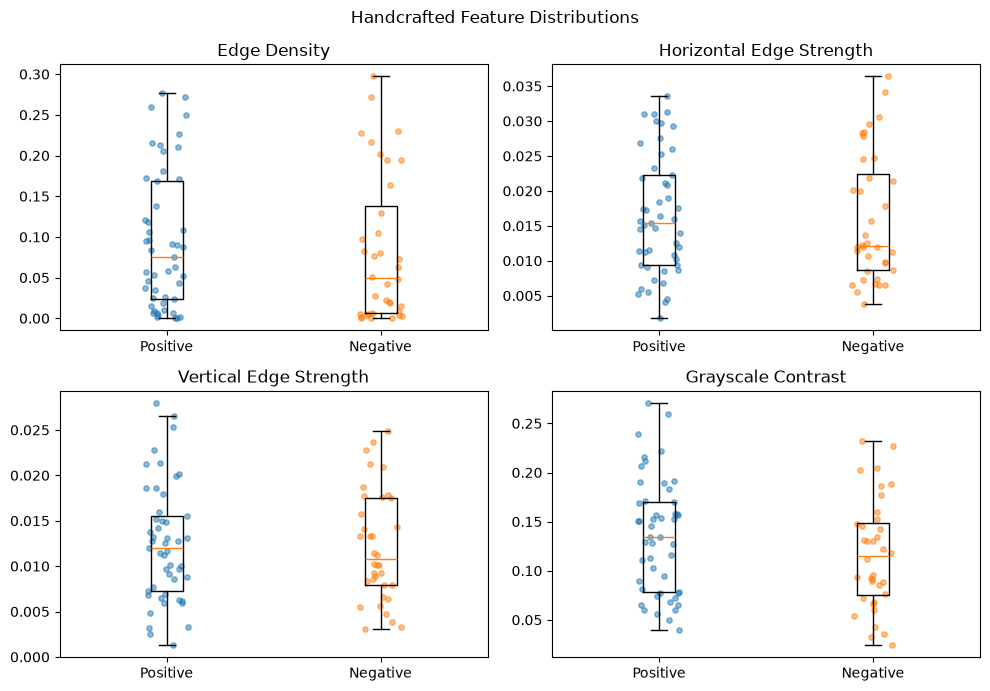

In [7]:
# Compare original training feature distributions.
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
rng = np.random.default_rng(SEED)

for ax, feature in zip(axes.flat, main_features):
    groups = [
        training_features.loc[training_features["class"] == label, feature].to_numpy()
        for label in LABELS
    ]
    ax.boxplot(groups, showfliers=False)
    for position, values in enumerate(groups, start=1):
        ax.scatter(position + rng.uniform(-0.1, 0.1, len(values)),
                   values, alpha=0.5, s=15)
    ax.set_xticks([1, 2], ["Positive", "Negative"])
    ax.set_title(feature.replace("_", " ").title())

fig.suptitle("Handcrafted Feature Distributions")
plt.tight_layout()
plt.show()


From the box plots, we can see it shows substantial overalp positive and neagtive across all four features. 
This suggests that individual handcraft features may not be sufficient to distinguish human-made stone structures from natural rocks. However, combining multiple features with a decision tree may improve classification.


### 4.3 Decision Tree Training and Cross-validation

A Decision Tree makes predictions by repeatedly splitting the data
based on feature values. 
And for spliting, I decided to use Gini impurity here :
$$
G = 1 - \sum_{k=1}^{K} p_k^2
$$

where $p_k$ represents the proportion of samples belonging to
class $k$ in a node.

Another important parameter is `max_depth`, it controls how deep
the tree can grow. A deeper tree can learn more complex patterns,
but it may also overfit the training data.

To find a suitable depth, I tested values from 2 to 6 using
5-fold cross-validation. For each fold, I compared training
and validation F1 scores to evaluate generalization.


In [8]:
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

TREE_DEPTHS = [2, 3, 4, 5, 6]
TREE_CONDITIONS = ["original", "augmented_10x"]

original_frame = training_features.copy()
original_frame["label"] = (original_frame["class"] == "positive").astype(int)
original_frame["source_id"] = (
    original_frame["class"] + "/" + original_frame["filename"]
)

X_original = original_frame[list(FEATURE_NAMES)].to_numpy()
y_original = original_frame["label"].to_numpy()
source_ids = original_frame["source_id"].to_numpy()
print("Original feature matrix:", X_original.shape)


Original feature matrix: (85, 10)


In [9]:
# Keep every augmented image associated with its original source.
augmented_rows = []
for label in LABELS:
    for path in image_paths["train_augmented", label]:
        source_name = path.stem.split("_aug_")[0] + ".jpg"
        augmented_rows.append({
            "filename": path.name, "class": label,
            "label": int(label == "positive"), "path": path,
            "source_id": f"{label}/{source_name}"
        })

augmented_records = pd.DataFrame(augmented_rows)
counts = augmented_records.groupby("source_id").size()
assert set(counts.index) == set(source_ids) and (counts == 10).all()

# Keep this CSV as a computational cache, not a report output. 
#I do this step because sometimes I will restart the kernel and I don't want to wait for running again.

cache_file = PROJECT_ROOT / ".cache" / "decision_tree" / "augmented_features.csv"
if cache_file.exists():
    augmented_features = pd.read_csv(cache_file)
else:
    augmented_features = pd.DataFrame([
        {"filename": row["filename"], "class": row["class"],
         **extract_image_features(row["path"])}
        for row in augmented_rows
    ])
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    augmented_features.to_csv(cache_file, index=False)

augmented_frame = augmented_records.merge(
    augmented_features, on=["filename", "class"], validate="one_to_one"
)
assert len(augmented_frame) == len(augmented_records)

X_augmented = augmented_frame[list(FEATURE_NAMES)].to_numpy(dtype=float)
y_augmented = augmented_frame["label"].to_numpy()
augmented_source_ids = augmented_frame["source_id"].to_numpy()
print("Augmented feature matrix:", X_augmented.shape)


Augmented feature matrix: (850, 10)


,condition,max_depth,mean_train_f1,mean_validation_f1,std_validation_f1
0,augmented_10x,2,0.7261,0.6015,0.1566
1,augmented_10x,3,0.7861,0.5927,0.1077
2,augmented_10x,4,0.8333,0.6541,0.1728
3,augmented_10x,5,0.8725,0.5967,0.1415
4,augmented_10x,6,0.9094,0.6461,0.0796
5,original,2,0.7500,0.5638,0.2040
6,original,3,0.8282,0.5270,0.1546
7,original,4,0.8718,0.5717,0.1356
8,original,5,0.9381,0.5925,0.0620
9,original,6,0.9744,0.5439,0.1412


Selected depths: {'original': {'max_depth': 5, 'random_state': 156}, 'augmented_10x': {'max_depth': 4, 'random_state': 156}}


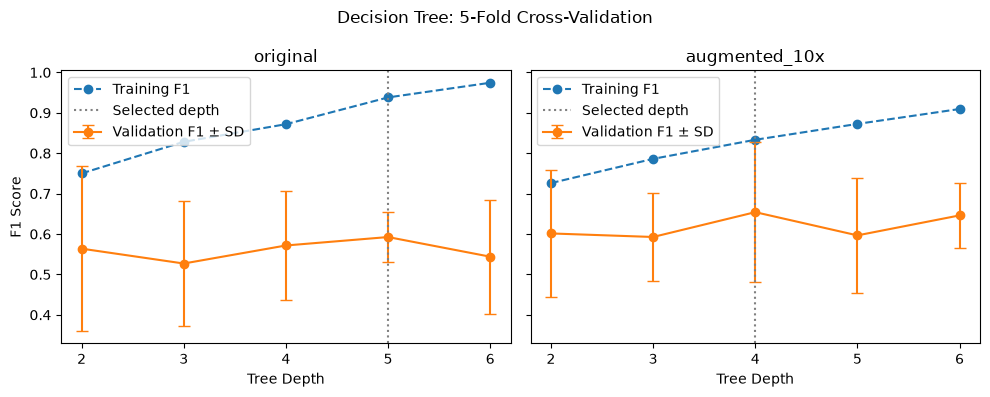

In [10]:
# Select tree depth using five shared original-image folds.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_original, y_original))
fold_rows = []

for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    aug_mask = np.isin(augmented_source_ids, source_ids[train_idx])
    assert aug_mask.sum() == 10 * len(train_idx)

    training_sets = {
        "original": (X_original[train_idx], y_original[train_idx]),
        "augmented_10x": (X_augmented[aug_mask], y_augmented[aug_mask])
    }
    for condition, (X_train, y_train) in training_sets.items():
        for depth in TREE_DEPTHS:
            model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
            model.fit(X_train, y_train)
            fold_rows.append({
                "fold": fold, "condition": condition, "max_depth": depth,
                "train_f1": f1_score(y_train, model.predict(X_train)),
                "validation_f1": f1_score(
                    y_original[val_idx], model.predict(X_original[val_idx])
                )
            })

cv_fold_results = pd.DataFrame(fold_rows)
cv_summary = cv_fold_results.groupby(
    ["condition", "max_depth"], as_index=False
).agg(
    mean_train_f1=("train_f1", "mean"),
    mean_validation_f1=("validation_f1", "mean"),
    std_validation_f1=("validation_f1", "std")
)

selected_parameters = {}
for condition in TREE_CONDITIONS:
    best = cv_summary[cv_summary["condition"] == condition].sort_values(
        ["mean_validation_f1", "max_depth"], ascending=[False, True]
    ).iloc[0]
    selected_parameters[condition] = {
        "max_depth": int(best["max_depth"]), "random_state": SEED
    }

display(cv_summary.round(4))
print("Selected depths:", selected_parameters)

# Plot training and validation scores across tree depths.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, condition in zip(axes, TREE_CONDITIONS):
    data = cv_summary[cv_summary["condition"] == condition].sort_values("max_depth")
    ax.plot(data["max_depth"], data["mean_train_f1"], "o--", label="Training F1")
    ax.errorbar(data["max_depth"], data["mean_validation_f1"],
                yerr=data["std_validation_f1"], fmt="o-", capsize=4,
                label="Validation F1 ± SD")
    ax.axvline(selected_parameters[condition]["max_depth"],
               color="gray", linestyle=":", label="Selected depth")
    ax.set(title=condition, xlabel="Tree Depth", xticks=TREE_DEPTHS)
    ax.legend()

axes[0].set_ylabel("F1 Score")
fig.suptitle("Decision Tree: 5-Fold Cross-Validation")
plt.tight_layout()
plt.show()


For original data here, the best tree depth was 5. Why we don't choose depth=6. This is because although the train-f1 is increasing, the validation-f1 is decreasing. This suggests overfitting.

For the 10× augmented dataset, depth 4 achieved the highest mean validation F1 (0.6541). However, its higher standard deviation (0.1728) indicates greater variation in performance across the five folds. Although depth 6 showed more consistent results, depth 4 was selected because it had the highest mean validation F1.



In [11]:
# Fit the final trees using the selected depths and all training data.
final_trees = {}
training_sets = {
    "original": (X_original, y_original),
    "augmented_10x": (X_augmented, y_augmented)
}
for condition, (X_train, y_train) in training_sets.items():
    model = DecisionTreeClassifier(**selected_parameters[condition])
    model.fit(X_train, y_train)
    final_trees[condition] = model


### 4.4 Final Test Evaluation

After selecting the best tree depth through cross-validation,
I evaluated both Decision Trees on the same 22 unseen test images.

I used Accuracy, Precision, Recall, and F1 Score to evaluate
classification performance, with positive-class F1 as the
primary metric.

$$
Precision = \frac{TP}{TP + FP}
$$

$$
Recall = \frac{TP}{TP + FN}
$$

$$
F1 = \frac{2 \times Precision \times Recall}{Precision + Recall}
$$

I also included a majority-class baseline that always predicts
Positive, since Positive was the most common class in the training
set. This provides a simple reference for evaluating whether the
Decision Trees learned useful classification patterns.

In [12]:
# Evaluate Decision Trees and a training-majority baseline.
test_rows = [
    {"filename": path.name, "class": label,
     "label": int(label == "positive"), "path": path}
    for label in LABELS for path in image_paths["test", label]
]
test_records = pd.DataFrame(test_rows)
test_features = pd.DataFrame([
    extract_image_features(path) for path in test_records["path"]
])
X_test = test_features[list(FEATURE_NAMES)].to_numpy()
y_test = test_records["label"].to_numpy()

test_predictions = {
    condition: model.predict(X_test) for condition, model in final_trees.items()
}
majority_label = int(np.bincount(y_original).argmax())
test_predictions["majority_baseline"] = np.full(len(y_test), majority_label)

metric_rows = []
for condition, predictions in test_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    metric_rows.append({
        "condition": condition, "test_images": len(y_test),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    })

test_metrics = pd.DataFrame(metric_rows)
display(test_metrics.round(4))


,condition,test_images,accuracy,precision,recall,f1,tn,fp,fn,tp
0,original,22,0.4545,0.5294,0.6923,0.6000,1,8,4,9
1,augmented_10x,22,0.5455,0.6000,0.6923,0.6429,3,6,4,9
2,majority_baseline,22,0.5909,0.5909,1.0000,0.7429,0,9,0,13


From the table above we can see the original decision tree had a test f1 of 0.6, while 10*data improved it slightly to 0.6429. The augumented model reduced false positives from 8 to 6, and both models still missed 4 positive images.

However, neither model outperformed the majority-class baseline(F1=0.7429), which simply predicted every image as positive.(!!! A horrible outcome)

Overall, these results suggest that simple hand crafted features may not be a good way to distinguish these two classes. The small test set of 22 images also limites how much we can generalize these findings.


## 5. Model 2: DINOv2 + Logistic Regression

### 5.1 Model Selection and Method

The Decision Tree results suggested that simple handcrafted features might not capture the shapes and spatial arrangements of stone structures.

Before choosing my second model, I considers several cv approachese(Let Ai give me the link of the paper and explain them to me), including HOG, Resnet18,CLIP, and DINOV2.

And HOG here uses handcrafted gradient feature, this is similar to the features explored in my first model, so FALSE!

Resnet 18 is a traditional CNN commonly pretrained with label images, not so interesting, so FALSE!

CLIP learns visual representations through image-text relationships, but I didn't use text here, so FALSE!

Dinov2, it uses self-supervised learning to extract visual features without requiring human-assigned class labels. Here I can use it to explore whether these pre-trained visual features could be useful for my dataset. Emm, interesting! Let's do this!

And here I used the pretrained DINOv2 Small (ViT-S/14) model as a
frozen feature extractor. Instead of retraining the neural
network, I used it to convert each image into a
384-dimensional feature vector. Fine-tuning the entire network on only 85 original training images could increase overfitting risk.

$$
\mathbf{z} = f_{\mathrm{DINOv2}}(\mathbf{x})
$$

Here, $\mathbf{x}$ represents the input image, and
$f_{\mathrm{DINOv2}}$ is the pretrained feature extraction function.
The output $\mathbf{z} \in \mathbb{R}^{384}$ is a vector containing
384 numerical features learned by the pretrained model.

Unlike the handcrafted features in Model 1, these features are
not manually defined. They represent visual information learned
during DINOv2's self-supervised pretraining.

I then used Logistic Regression to predict whether the image
contains a recognizable human-made stone structure:

$$
P(y=1 \mid \mathbf{z})
= \frac{1}{1+e^{-(\mathbf{w}^T\mathbf{z}+b)}}
$$

Here:

- $y=1$ represents a positive image containing a recognizable
  human-made stone structure.
- $\mathbf{z}$ is the 384-dimensional feature vector from DINOv2.
- $\mathbf{w}$ contains the weights learned by Logistic Regression.
- $b$ is the bias term.

The expression $\mathbf{w}^T\mathbf{z}+b$ calculates a weighted
sum of the visual features. The sigmoid function then converts
this value into a probability between 0 and 1.

During training, Logistic Regression learns the weights and bias
using the labeled photographs, while DINOv2 remains frozen.



In [13]:
import torch
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from src.dinov2_features import load_backbone, EmbeddingCache

DINO_BATCH_SIZE = 8
DINO_C_VALUES = [0.01, 0.1, 1.0, 10.0]
DINO_CONDITIONS = ["original", "augmented_10x"]
torch.manual_seed(SEED)

DINO_CACHE = PROJECT_ROOT / ".cache" / "dinov2"
DINO_CACHE.mkdir(parents=True, exist_ok=True)

def dino_image_records(split):
    return [
        {"path": path, "filename": path.name, "class": label,
         "label": int(label == "positive"),
         "source_id": f"{label}/{path.name}"}
        for label in LABELS for path in image_paths[split, label]
    ]

dino_original_records = dino_image_records("train")
dino_original_ids = np.array([row["source_id"] for row in dino_original_records])
dino_y_original = np.array([row["label"] for row in dino_original_records])

# Fold indices are valid only if original images have the same order.
assert np.array_equal(dino_original_ids, source_ids)
dino_folds = cv_splits
print("DINOv2 original images:", len(dino_original_records))


DINOv2 original images: 85


In [14]:
# Load frozen pretrained DINOv2 and prepare its embedding cache.
dino_model, dino_device, dino_config = load_backbone(DINO_CACHE)
embedding_cache = EmbeddingCache(
    DINO_CACHE, dino_model, dino_device, dino_config
)
print(f"DINOv2: {dino_config['model']} on {dino_device}")
print("Embedding dimension:", dino_model.embed_dim)


./.cache/dinov2/torch_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
./.cache/dinov2/torch_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
./.cache/dinov2/torch_hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


DINOv2: dinov2_vits14 on mps
Embedding dimension: 384


### 5.2 Feature Extraction and Caching
Before feature extraction, each image is resized and padded
to 224 × 224 pixels while preserving its aspect ratio.
The images are then normalized and passed through the
pretrained DINOv2 model.

I processed the images in batches of 8. Each image was
converted into a 384-dimensional feature vector.

Since extracting features with DINOv2 takes time, I used
a cache to save the embeddings and avoid repeating the
same computation.

In [15]:
# Extract or reuse 384-dimensional training embeddings.
dino_X_original, _ = embedding_cache.extract(
    dino_original_records, "train_original", batch_size=DINO_BATCH_SIZE
)

dino_augmented_records = dino_image_records("train_augmented")
for row in dino_augmented_records:
    original_name = Path(row["filename"]).stem.split("_aug_")[0] + ".jpg"
    row["source_id"] = f"{row['class']}/{original_name}"

dino_augmented_ids = np.array([row["source_id"] for row in dino_augmented_records])
dino_y_augmented = np.array([row["label"] for row in dino_augmented_records])

dino_X_augmented, _ = embedding_cache.extract(
    dino_augmented_records, "train_augmented", batch_size=DINO_BATCH_SIZE
)
print("DINOv2 original embeddings:", dino_X_original.shape)
print("DINOv2 augmented embeddings:", dino_X_augmented.shape)


train_original: 85 rows, 0 new embeddings, 85 reused.


train_augmented: 850 rows, 0 new embeddings, 850 reused.


DINOv2 original embeddings: (85, 384)
DINOv2 augmented embeddings: (850, 384)


### 5.3 Logistic Regression selection
Since DINOv2 was frozen, Logistic Regression was the only
part of this pipeline that learned from my labeled dataset.

I used L2 regularization to reduce the risk of overfitting because there are 384 features but only 85 independent original training images.
The loss function can be written as:

$$
\mathcal{L}
=
-\frac{1}{n}\sum_{i=1}^{n}
\left[
y_i\log(p_i)+(1-y_i)\log(1-p_i)
\right]
+
\frac{\lambda}{2}\sum_{j=1}^{384}w_j^2
$$

Here:

- $\mathcal{L}$ is the total loss that the model minimizes.
- $n$ is the number of training images.
- $i$ indexes each training image, from 1 to $n$.
- $y_i$ is the true label of image $i$ (1 = Positive, 0 = Negative).
- $p_i$ is the predicted probability that image $i$ is Positive.
- $\log$ is the natural logarithm.
- $j$ indexes the 384 DINOv2 features.
- $w_j$ is the learned weight for feature $j$.
- $\lambda$ controls the strength of L2 regularization.

The first term is Cross-Entropy Loss, which measures the
difference between the predicted probabilities and the
true labels.

The second term is the L2 penalty. It penalizes large
weights by adding the sum of their squares to the loss.

A larger $\lambda$ means stronger regularization, which
encourages smaller weights and may reduce overfitting.

In scikit-learn, regularization is controlled by C,
which is inversely related to its strength:

$$
\lambda \propto \frac{1}{C}
$$

Therefore, a smaller C means stronger regularization,
while a larger C means weaker regularization.

I tested four values:

C = [0.01, 0.1, 1, 10]

Similar to the Decision Tree experiment, I used 5-fold
cross-validation to select the best C based on the average
validation F1 score.

I also used StandardScaler to standardize the features
before classification. The scaler was fitted separately
within each training fold to avoid data leakage.

$$
z'_{ij} = \frac{z_{ij}-\mu_j}{\sigma_j}
$$

Here:

- $i$ is the index of a training image, from 1 to $n$.
- $j$ is the index of a DINOv2 feature, from 1 to 384.
- $n$ is the number of images in the current training fold.
- $z_{ij}$ is the original value of feature $j$ for image $i$.
- $\mu_j$ is the mean of feature $j$ across the training images.
- $\sigma_j$ is the standard deviation of feature $j$.
- $z'_{ij}$ is the standardized feature value.

The mean and standard deviation are calculated as:

$$
\mu_j = \frac{1}{n}\sum_{i=1}^{n}z_{ij}
$$

$$
\sigma_j =
\sqrt{\frac{1}{n}\sum_{i=1}^{n}(z_{ij}-\mu_j)^2}
$$

This transformation makes the features have approximately
the same scale. For features with nonzero variance, the
training mean becomes 0 and the standard deviation becomes 1.



,condition,C,mean_train_f1,mean_validation_f1,std_validation_f1
0,augmented_10x,0.01,0.9982,0.7786,0.1660
1,augmented_10x,0.10,1.0000,0.7856,0.1162
2,augmented_10x,1.00,1.0000,0.7611,0.0960
3,augmented_10x,10.00,1.0000,0.7047,0.1162
4,original,0.01,0.9530,0.8018,0.1226
5,original,0.10,1.0000,0.7511,0.1252
6,original,1.00,1.0000,0.7398,0.1201
7,original,10.00,1.0000,0.7398,0.1201


Selected C: {'original': 0.01, 'augmented_10x': 0.1}


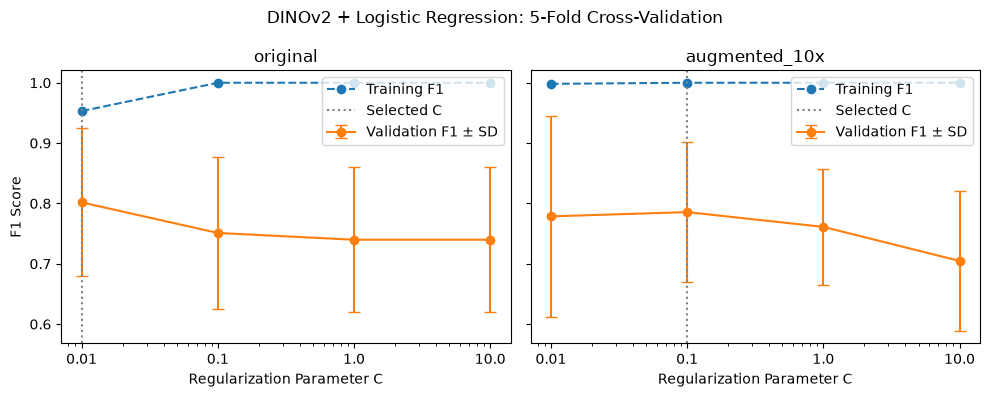

In [16]:
# Standardize features within each fold, then train L2 Logistic Regression.
def make_dino_classifier(C):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=C, solver="lbfgs", max_iter=2000, random_state=SEED
        ))
    ])

cv_rows = []
for fold, (train_idx, val_idx) in enumerate(dino_folds, start=1):
    aug_mask = np.isin(dino_augmented_ids, dino_original_ids[train_idx])
    assert aug_mask.sum() == 10 * len(train_idx)

    training_sets = {
        "original": (dino_X_original[train_idx], dino_y_original[train_idx]),
        "augmented_10x": (dino_X_augmented[aug_mask], dino_y_augmented[aug_mask])
    }

    for condition, (X_train, y_train) in training_sets.items():
        for C in DINO_C_VALUES:
            model = make_dino_classifier(C)
            model.fit(X_train, y_train)
            cv_rows.append({
                "condition": condition, "C": C, "fold": fold,
                "train_f1": f1_score(y_train, model.predict(X_train)),
                "validation_f1": f1_score(
                    dino_y_original[val_idx], model.predict(dino_X_original[val_idx])
                )
            })

dino_cv_folds = pd.DataFrame(cv_rows)
dino_cv_summary = dino_cv_folds.groupby(
    ["condition", "C"], as_index=False
).agg(
    mean_train_f1=("train_f1", "mean"),
    mean_validation_f1=("validation_f1", "mean"),
    std_validation_f1=("validation_f1", "std")
)

dino_selected_C = {}
for condition in DINO_CONDITIONS:
    best = dino_cv_summary[dino_cv_summary["condition"] == condition].sort_values(
        ["mean_validation_f1", "C"], ascending=[False, True]
    ).iloc[0]
    dino_selected_C[condition] = float(best["C"])

display(dino_cv_summary.round(4))
print("Selected C:", dino_selected_C)

# Plot training and validation scores across C values.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, condition in zip(axes, DINO_CONDITIONS):
    data = dino_cv_summary[dino_cv_summary["condition"] == condition].sort_values("C")
    ax.plot(data["C"], data["mean_train_f1"], "o--", label="Training F1")
    ax.errorbar(data["C"], data["mean_validation_f1"],
                yerr=data["std_validation_f1"], fmt="o-", capsize=4,
                label="Validation F1 ± SD")
    ax.axvline(dino_selected_C[condition], color="gray",
               linestyle=":", label="Selected C")
    ax.set_xscale("log")
    ax.set_xticks(DINO_C_VALUES)
    ax.set_xticklabels([str(c) for c in DINO_C_VALUES])
    ax.set_title(condition)
    ax.set_xlabel("Regularization Parameter C")
    ax.legend()

axes[0].set_ylabel("F1 Score")
fig.suptitle("DINOv2 + Logistic Regression: 5-Fold Cross-Validation")
plt.tight_layout()
plt.show()


In [17]:
# Fit final classifiers with the selected C values.
dino_final_models = {}
training_sets = {
    "original": (dino_X_original, dino_y_original),
    "augmented_10x": (dino_X_augmented, dino_y_augmented)
}
for condition, (X_train, y_train) in training_sets.items():
    model = make_dino_classifier(dino_selected_C[condition])
    model.fit(X_train, y_train)
    dino_final_models[condition] = model
    print(f"{condition}: fitted with C={dino_selected_C[condition]}")


original: fitted with C=0.01
augmented_10x: fitted with C=0.1


### 5.4 Final Test Evaluation

After selecting the best C values through cross-validation,
I evaluated both final DINOv2 classifiers on the 22 held-out
test images.

The test images were first converted into 384-dimensional
features using the same frozen DINOv2 model.

I evaluated the models using Accuracy, Precision, Recall,
F1 Score, and Confusion Matrices.

I also compared the DINOv2 results with the Decision Tree
results and the majority-class baseline. All models were
evaluated on the same 22 test images.

test_original: 22 rows, 0 new embeddings, 22 reused.


,model,condition,accuracy,precision,recall,f1,balanced_accuracy,tn,fp,fn,tp
0,Decision Tree,original,0.4545,0.5294,0.6923,0.6000,0.4017,1,8,4,9
1,Decision Tree,augmented_10x,0.5455,0.6000,0.6923,0.6429,0.5128,3,6,4,9
2,Majority Baseline,majority_baseline,0.5909,0.5909,1.0000,0.7429,0.5000,0,9,0,13
3,DINOv2 + Logistic Regression,original,0.9545,0.9286,1.0000,0.9630,0.9444,8,1,0,13
4,DINOv2 + Logistic Regression,augmented_10x,0.9545,0.9286,1.0000,0.9630,0.9444,8,1,0,13


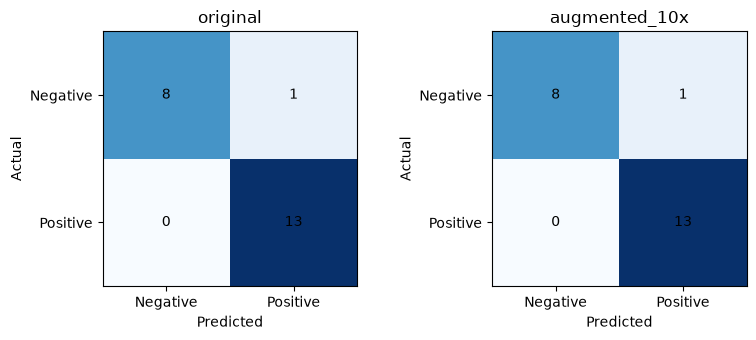

In [18]:
# Extract held-out test embeddings only after final model fitting.
dino_test_records = dino_image_records("test")
assert [
    (row["class"], row["filename"]) for row in dino_test_records
] == list(zip(test_records["class"], test_records["filename"]))

dino_y_test = np.array([row["label"] for row in dino_test_records])
dino_X_test, _ = embedding_cache.extract(
    dino_test_records, "test_original", batch_size=DINO_BATCH_SIZE
)

dino_predictions = {}
metric_rows = []
for condition, model in dino_final_models.items():
    predictions = model.predict(dino_X_test)
    dino_predictions[condition] = predictions
    tn, fp, fn, tp = confusion_matrix(
        dino_y_test, predictions, labels=[0, 1]
    ).ravel()
    metric_rows.append({
        "condition": condition,
        "accuracy": accuracy_score(dino_y_test, predictions),
        "precision": precision_score(dino_y_test, predictions),
        "recall": recall_score(dino_y_test, predictions),
        "f1": f1_score(dino_y_test, predictions),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
    })

dino_test_metrics = pd.DataFrame(metric_rows)

# Compare both pipelines and the majority-class baseline.
tree_results = test_metrics.copy()
tree_results["model"] = "Decision Tree"
tree_results.loc[tree_results["condition"] == "majority_baseline",
                 "model"] = "Majority Baseline"

dino_results = dino_test_metrics.copy()
dino_results["model"] = "DINOv2 + Logistic Regression"
model_comparison = pd.concat([tree_results, dino_results], ignore_index=True)

model_comparison["balanced_accuracy"] = (
    model_comparison["recall"]
    + model_comparison["tn"] / (model_comparison["tn"] + model_comparison["fp"])
) / 2

display(model_comparison[[
    "model", "condition", "accuracy", "precision",
    "recall", "f1", "balanced_accuracy", "tn", "fp", "fn", "tp"
]].round(4))

# DINOv2 confusion matrices.
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, condition in zip(axes, DINO_CONDITIONS):
    cm = confusion_matrix(dino_y_test, dino_predictions[condition], labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    ax.set(xticks=[0, 1], yticks=[0, 1],
           xticklabels=["Negative", "Positive"],
           yticklabels=["Negative", "Positive"],
           xlabel="Predicted", ylabel="Actual", title=condition)

plt.tight_layout()
plt.show()


In [19]:
# Identify misclassified test images.
for condition, predictions in dino_predictions.items():
    mistakes = [
        row["filename"] for row, prediction in zip(dino_test_records, predictions)
        if row["label"] != prediction
    ]
    print(f"{condition}: {mistakes}")


original: ['negative_037.jpg']
augmented_10x: ['negative_037.jpg']


### 5.5 DINOv2 Results and Discussion

Cross-validation selected C = 0.01 for the original condition
and C = 0.1 for the augmented condition. Their mean validation
F1 scores were 0.8018 and 0.7856, respectively.

On the 22 test images, both DINOv2 models achieved an F1 score
of 0.9630 and an accuracy of 0.9545. Both correctly identified
all 13 positive images and 8 of the 9 negative images.
The only false positive was negative_037.jpg.

Compared with the Decision Tree models and the majority-class
baseline, DINOv2 + Logistic Regression performed much better
on this test set. This suggests that pretrained visual features
may be more useful than simple handcrafted features for
recognizing stone structures.

Interestingly, data augmentation did not improve DINOv2's
test performance. However, since the test set contains only
22 images, these results may not generalize to a larger dataset.

### 5.6 Error Analysis: A False Positive

Both DINOv2 models made the same mistake on `negative_037.jpg`.
The image was labeled Negative because it does not contain a
recognizable human-made stone structure, but both models
predicted Positive.

*The source photograph is omitted from this public repository to protect the privacy of the dataset.*

Interestingly, this photograph contains a natural landscape,
animals, and a fence, but no recognizable stone structure.
The model might have confused some of these visual patterns
with human-made stone structures.

This example shows that even though DINOv2 achieved a high
F1 score, it can still make mistakes when interpreting
complex field photographs.

## 6. Overall Discussion and Conclusion

In this project, I compared handcrafted features with pretrained
DINOv2 features for identifying human-made stone structures in
my field photographs.

DINOv2 + Logistic Regression performed much better than the
Decision Tree, achieving a test F1 of 0.9630 compared with
0.6000–0.6429. Data augmentation slightly improved the Decision
Tree but did not improve DINOv2's test performance.

Overall, pretrained visual features seem promising for this task.
However, the dataset is small, with only 22 test images, so more
independent photographs are needed to evaluate generalization.
The two pipelines also used different classifiers, which limits
how much of the performance difference can be attributed to
feature extraction alone.

---

### 🎩 A Phantom Thief's Calling Card

*Ladies and gentlemen,*

*My first heist was not quite as spectacular as I had imagined. Poor time management left me with a dataset far too small to truly enjoy the game.*

*But a phantom thief never reveals all his tricks in the first act.*

*Two new pipelines are already taking shape, and I have begun hunting for the data they deserve.*

*Consider this my official warning: the next performance will be far more interesting.*

*Until we meet again under the moonlight...*

**— The Phantom Thief of Data 🃏**

## 7. References

Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984).
*Classification and regression trees*. Wadsworth International Group.
https://books.google.com/books?id=JwQx-WOmSyQC

Dalal, N., & Triggs, B. (2005).
Histograms of oriented gradients for human detection.
*IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*.
https://doi.org/10.1109/CVPR.2005.177

Friedman, J., Hastie, T., & Tibshirani, R. (2010).
Regularization paths for generalized linear models via coordinate descent.
*Journal of Statistical Software, 33*(1), 1–22.
https://doi.org/10.18637/jss.v033.i01

Gonzalez, R. C., & Woods, R. E. (2018).
*Digital image processing* (4th ed.). Pearson.
https://books.google.com/books?id=0F05vgAACAAJ

He, K., Zhang, X., Ren, S., & Sun, J. (2016).
Deep residual learning for image recognition.
*IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*.
https://arxiv.org/abs/1512.03385

Meta AI Research. (n.d.).
*DINOv2: Official PyTorch implementation and pretrained models*
[Source code]. GitHub.
https://github.com/facebookresearch/dinov2

Oquab, M., et al. (2024).
DINOv2: Learning robust visual features without supervision.
*Transactions on Machine Learning Research*.
https://arxiv.org/abs/2304.07193

Pedregosa, F., et al. (2011).
Scikit-learn: Machine learning in Python.
*Journal of Machine Learning Research, 12*, 2825–2830.
https://jmlr.org/papers/v12/pedregosa11a.html

Radford, A., et al. (2021).
Learning transferable visual models from natural language supervision.
*International Conference on Machine Learning (ICML)*.
https://proceedings.mlr.press/v139/radford21a.html

Shorten, C., & Khoshgoftaar, T. M. (2019).
A survey on image data augmentation for deep learning.
*Journal of Big Data, 6*, Article 60.
https://doi.org/10.1186/s40537-019-0197-0